# CHILLED — EDA: ASHRAE RP-1043 Chiller Fault Dataset

Source folder: `opensource_dataset/ASHRAE/`

ASHRAE Research Project **1043-RP** ("Fault Detection and Diagnostic Requirements and Evaluation
Tools for Chillers", Comstock & Braun, 1999) is a *laboratory* fault-injection campaign on a
**90-ton centrifugal water-cooled chiller**. Between **1999-08-19** and **1999-11-09** the team ran
59 full-day test sequences. In each test the chiller was driven through a grid of operating
points (load × condenser/evaporator water temperature) while **one fault was physically
introduced at a controlled severity** — tubes plugged in the condenser, refrigerant removed or
added, water flow throttled, oil overcharged, nitrogen injected.

This is the key structural difference to a building-telemetry dataset: it is **not continuous
operation**. It is 60 discontinuous ~14.4 h experiments, each one a labelled `(fault type,
severity)` pair, sampled at **10 s**.

### What this notebook does
1. Builds a catalogue of all test runs from `read me first.xls` (name → date → fault family).
2. Picks **one healthy** and **one faulty** series and profiles them
   (min/max/mean, nulls, sampling rate, gaps, constant channels, redundancy).
3. Builds the **correlation matrix plot** (same idiom as `eda.ipynb`) for both series, plus the
   healthy→faulty correlation *shift*.
4. Runs **PCA on the healthy series**, then projects everything into that basis and plots
   **PC1–PC3** over the **whole campaign** and over a **single test day**.

### Series chosen
| role | file | date | why |
|---|---|---|---|
| **healthy** | `normal1` | 1999-09-16 | the read-me calls it *"the reference standard"* — all operating conditions met |
| **faulty**  | `cf30`    | 1999-10-20 | condenser fouling, 49 of 164 condenser tubes plugged (~30 %); a clean, strong, well-documented fault |

Runs marked *aborted*, *alt* or *"never reached steady state"* in the read-me are deliberately
avoided for the deep dive (they are still kept in the campaign-wide view).

In [1]:
import glob
import os
import re

import numpy as np
import polars as pl
import fastexcel

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

ASHRAE_DIR = "opensource_dataset/ASHRAE"
SHEET = "Complete Data Set"   # 10 s raw samples ("Reduced Data Set" is the 1-min averaged version)

HEALTHY = "normal1"
FAULTY = "cf30"

pl.Config.set_tbl_rows(20)

polars.config.Config

## 1. Test catalogue

`read me first.xls` is the campaign log: one row per test run with its date and a free-text
comment. The *fault family* is not in that file — it is encoded in the directory each `.xls`
sits in (`Condenser fouling/`, `Refrigerant leak/`, …), so we join the two.

A handful of files carry a `--unsteady test…` suffix that the read-me does not use, so the join
falls back to matching on the part of the filename before `--`.

In [2]:
readme = (
    fastexcel.read_excel(f"{ASHRAE_DIR}/read me first.xls")
    .load_sheet(0, header_row=0)
    .to_polars()
    .rename({"File name": "test", "Date of Test": "test_date", "Comments": "comment"})
    .filter(pl.col("test") != "End of testing")
    .with_columns(pl.col("test_date").cast(pl.Date))
)

# every .xls under the ASHRAE folder is one test run; its parent folder is the fault family
files = [
    f for f in glob.glob(f"{ASHRAE_DIR}/**/*.xls", recursive=True)
    if os.path.basename(f) != "read me first.xls"
]

catalogue = pl.DataFrame(
    {
        "path": files,
        "stem": [os.path.splitext(os.path.basename(f))[0] for f in files],
        "fault_family": [os.path.basename(os.path.dirname(f)) for f in files],
    }
).with_columns(
    # "fwe20 alt--unsteady test5" -> "fwe20 alt" so it joins onto the read-me
    pl.col("stem").str.split("--").list.first().alias("test")
)

catalogue = (
    catalogue.join(readme, on="test", how="left")
    .with_columns(pl.col("fault_family").replace({"Benchmark Tests": "Normal / benchmark"}))
    .sort("test_date")
)

print(f"{catalogue.height} test runs, "
      f"{catalogue['test_date'].min()} -> {catalogue['test_date'].max()}")
catalogue.group_by("fault_family").len().sort("len", descending=True)

59 test runs, 1999-08-19 -> 1999-11-09


fault_family,len
str,u32
"""Normal / benchmark""",18
"""Non-condensables in refrigeran…",8
"""Excess oil""",6
"""Reduced evaporator water flow""",6
"""Condenser fouling""",5
"""Refrigerant leak""",5
"""Reduced condenser water flow""",5
"""Refrigerant overcharge""",4
"""Defective Pilot Valve""",1


In [3]:
with pl.Config(tbl_rows=-1, fmt_str_lengths=70):
    display(catalogue.select("test_date", "test", "fault_family", "comment"))

test_date,test,fault_family,comment
date,str,str,str
1999-08-19,"""defective pilot valve""","""Defective Pilot Valve""","""Originally the 9th complete test run; the last one before the pilot va…"
1999-08-25,"""normal dpv""","""Normal / benchmark""","""Originally the 12th complete test run; new pilot valve properly adjust…"
1999-09-02,"""fwc30""","""Reduced condenser water flow""","""Condenser water flow rate reduced by 30%; was able to perform test wit…"
1999-09-03,"""fwc40""","""Reduced condenser water flow""","""Condenser water flow rate reduced by 40%; was able to perform test wit…"
1999-09-09,"""near normal3""","""Normal / benchmark""","""The worst of the corrected condenser water flow rate tests; hence it w…"
1999-09-10,"""near normal1""","""Normal / benchmark""","""Test run under normal conditions; however, not all the desired operati…"
1999-09-11,"""near normal2""","""Normal / benchmark""","""Test run under normal conditions; however, not all the desired operati…"
1999-09-12,"""normal""","""Normal / benchmark""","""The first test run where all operating conditions were met"""
1999-09-13,"""fwc10""","""Reduced condenser water flow""","""Condenser water flow rate reduced by 10%"""


## 2. Loading a single test

Each workbook has six sheets; only two hold time series:

| sheet | content |
|---|---|
| `Complete Data Set` | **raw 10 s samples** for the whole test day — what we use |
| `Reduced Data Set` | the same run averaged to 1-minute rows |
| `Steady States` | one row per operating point, averaged over its steady-state window |
| `Reduced Graph`, `Regression`, `Power Curve Tables` | plotting / model-fitting scratch sheets |

`Time` is **elapsed seconds since the start of the test**, not a wall clock. We turn it into a
real timestamp with `test_date + Time seconds` so the campaign-wide plots can use a true date
axis.

In [4]:
def load_test(path: str, test_date, test: str, fault_family: str) -> pl.DataFrame:
    # load one RP-1043 workbook and attach a real timestamp + labels
    df = (
        fastexcel.read_excel(path)
        .load_sheet_by_name(SHEET, header_row=0)
        .to_polars()
    )
    # 5 of the early workbooks spell the heat-balance channel without its unit -> normalise
    if "Heat Balance" in df.columns and "Heat Balance (kW)" not in df.columns:
        df = df.rename({"Heat Balance": "Heat Balance (kW)"})
    return df.with_columns(
        (pl.lit(test_date).cast(pl.Datetime("us"))
         + pl.duration(milliseconds=(pl.col("Time") * 1000).round(0))).alias("timestamp"),
        pl.lit(test).alias("test"),
        pl.lit(fault_family).alias("fault_family"),
    )


def load_by_name(name: str) -> pl.DataFrame:
    row = catalogue.filter(pl.col("test") == name).row(0, named=True)
    return load_test(row["path"], row["test_date"], row["test"], row["fault_family"])


healthy = load_by_name(HEALTHY)
faulty = load_by_name(FAULTY)

print(f"healthy '{HEALTHY}': {healthy.shape}")
print(f"faulty  '{FAULTY}': {faulty.shape}")
healthy.head()

healthy 'normal1': (5191, 69)
faulty  'cf30': (5191, 69)


Time,TWE_set,TEI,TWEI,TEO,TWEO,TCI,TWCI,TCO,TWCO,TSI,TSO,TBI,TBO,Cond Tons,Cooling Tons,Shared Cond Tons,Cond Energy Balance,Evap Tons,Shared Evap Tons,Building Tons,Evap Energy Balance,kW,COP,kW/Ton,FWC,FWE,TEA,TCA,TRE,PRE,TRC,PRC,TRC_sub,T_suc,Tsh_suc,TR_dis,Tsh_dis,P_lift,Amps,RLA%,Heat Balance (kW),Heat Balance%,Tolerance%,Unit Status,Active Fault,TO_sump,TO_feed,PO_feed,PO_net,TWCD,TWED,VSS,VSL,VH,VM,VC,VE,VW,TWI,TWO,THI,THO,FWW,FWH,FWB,timestamp,test,fault_family
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,datetime[μs],str,str
3.586,50.0,64.12,64.2,64.96,65.0,65.8,65.6,66.49,66.5,68.76,70.73,67.74,68.34,1.1190e-46,3.6510e-46,3.1730e-46,7.9430e-46,1.0900e-46,3.5800e-46,7.7950e-47,5.4500e-46,1.6820e-45,3.8340e-46,1.6820e-45,3.8680e-45,3.0970e-45,0.0,0.0,64.9,64.1,64.9,64.1,0.0,81.8,16.9,71.5,6.8,0.0,0.0,0.0,0.0,0.0,23.27,1.0,29.0,108.4,87.3,59.6,0.0,0.9,0.0,0.0,0.0,100.0,100.0,57.0,56.0,0.0,67.48,70.73,69.22,71.78,2.6990e-45,7.3030e-46,-4.9630e-46,1999-09-16 00:00:03.586,"""normal1""","""Normal / benchmark"""
13.57,50.0,64.12,64.4,64.96,64.8,65.8,65.8,66.53,66.5,68.76,70.69,67.74,68.34,1.1850e-46,3.5850e-46,3.1070e-46,7.8770e-46,1.0900e-46,3.5800e-46,7.7950e-47,5.4500e-46,1.6820e-45,3.8340e-46,1.6820e-45,3.8680e-45,3.0970e-45,0.1,0.0,64.9,64.1,64.5,63.6,0.0,81.8,16.9,71.5,7.2,0.0,0.0,0.0,0.0,0.0,23.27,1.0,29.0,108.8,87.2,59.6,0.0,0.9,0.0,0.0,0.0,100.0,100.0,57.0,56.0,30.0,67.44,70.73,69.22,71.78,2.6170e-45,7.3030e-46,-5.8890e-46,1999-09-16 00:00:13.570,"""normal1""","""Normal / benchmark"""
23.57,50.0,64.16,65.8,64.96,64.8,65.84,67.9,66.49,66.2,68.76,70.64,67.74,68.34,4.13,14.32,11.93,30.38,4.498,15.52,3.379,23.4,1.6820e-45,15.81,3.7380e-46,151.7,134.2,0.0,1.5,65.1,64.4,67.7,68.0,0.0,82.0,16.6,71.7,3.8,2.2,0.0,0.0,1.296,8.923,23.27,1.0,29.0,108.8,87.3,60.1,0.0,0.0,1.0,0.0,0.0,100.0,100.0,57.0,56.0,30.0,67.44,70.77,70.37,71.49,103.3,71.85,-45.65,1999-09-16 00:00:23.570,"""normal1""","""Normal / benchmark"""
33.8,50.0,64.49,67.6,65.01,66.1,66.33,67.2,66.49,67.6,68.68,70.32,67.7,68.22,1.672,22.56,16.96,41.2,4.392,22.85,4.433,31.68,1.6820e-45,15.44,3.8280e-46,248.0,203.7,0.0,0.0,67.0,67.0,66.3,66.0,0.0,82.0,15.0,71.5,5.4,0.0,0.0,0.0,9.563,162.6,23.27,6.0,0.0,108.8,87.3,62.6,0.0,0.8,1.2,0.0,0.0,100.0,100.0,57.0,56.0,30.0,67.48,70.52,70.2,70.23,178.0,106.4,-86.12,1999-09-16 00:00:33.800,"""normal1""","""Normal / benchmark"""
43.57,50.0,65.14,66.4,65.37,66.8,66.53,66.5,66.78,66.7,68.31,69.42,67.37,67.73,2.676,16.77,12.17,31.62,2.062,17.83,3.202,23.1,1.6820e-45,7.25,8.1550e-46,263.4,214.3,0.9,0.0,65.6,65.1,66.3,66.5,0.0,82.2,16.7,71.7,5.4,1.6,0.0,0.0,-2.159,-22.94,23.27,6.0,0.0,109.0,87.3,60.1,0.0,0.0,0.0,0.0,0.0,100.0,100.0,57.0,56.0,30.0,67.52,69.91,69.26,69.37,168.7,76.84,-122.4,1999-09-16 00:00:43.570,"""normal1""","""Normal / benchmark"""


### 2.1 Two file-level quirks worth knowing

* **Schema drift.** 53 workbooks name the heat-balance channel `Heat Balance (kW)`; 5 of the
  earliest ones (`defective pilot valve`, `normal dpv`, `near normal3`, …) call it plain
  `Heat Balance`. Same quantity, different label — `load_test` normalises it, otherwise any
  attempt to concatenate the campaign fails.
* **One corrupt workbook.** `near normal1.xls` cannot be parsed (the underlying `.xls` RK record
  is truncated). It is skipped in the campaign-wide load and reported explicitly rather than
  silently dropped. 58 of the 59 runs are usable.

Apart from those two, all workbooks share an identical 66-column schema.

## 3. General description of the dataset

### 3.1 Shape, time span and sampling rate

In [5]:
def profile(df: pl.DataFrame, label: str) -> dict:
    ts = df["timestamp"]
    dt = df["Time"].diff().drop_nulls()
    span = ts.max() - ts.min()
    # a "gap" is any step more than 50 % longer than the nominal cadence
    nominal = dt.median()
    gaps = dt.filter(dt >= nominal * 2)   # a real gap = at least one sample missing
    return {
        "series": label,
        "rows": df.height,
        "columns": df.width,
        "start": str(ts.min()),
        "end": str(ts.max()),
        "duration_h": round(span.total_seconds() / 3600, 2),
        "dt_median_s": nominal,
        "dt_min_s": dt.min(),
        "dt_p01_s": dt.quantile(0.01),
        "dt_p99_s": dt.quantile(0.99),
        "dt_max_s": dt.max(),
        "pct_dt_exactly_nominal": round(100 * dt.filter(dt == nominal).len() / dt.len(), 1),
        "n_gaps_ge_2x": gaps.len(),
        "expected_rows_on_grid": int(round(span.total_seconds() / nominal)) + 1,
        "null_cells": int(df.null_count().sum_horizontal().item()),
        "nan_cells": int(sum(df[c].is_nan().sum() for c, t in df.schema.items() if t == pl.Float64)),
    }


overview = pl.DataFrame(
    [profile(healthy, f"healthy · {HEALTHY}"), profile(faulty, f"faulty · {FAULTY}")],
    schema_overrides={"start": pl.Utf8, "end": pl.Utf8},
)

with pl.Config(tbl_cols=-1, fmt_str_lengths=40):
    display(overview.transpose(include_header=True, column_names="series"))

column,healthy · normal1,faulty · cf30
str,str,str
"""rows""","""5191""","""5191"""
"""columns""","""69""","""69"""
"""start""","""1999-09-16 00:00:03.586000""","""1999-10-20 00:00:03.585000"""
"""end""","""1999-09-16 14:25:10""","""1999-10-20 14:25:10"""
"""duration_h""","""14.42""","""14.42"""
"""dt_median_s""","""10.0""","""10.0"""
"""dt_min_s""","""9.0""","""9.0"""
"""dt_p01_s""","""10.0""","""10.0"""
"""dt_p99_s""","""10.0""","""10.0"""


**Read-out**

* **Sampling rate: one sample every 10 s** (0.1 Hz). It is *almost* rigid — **~99 % of the steps
  are exactly 10 s**; the rest are 9 s or, at worst, 15 s. So the logger jitters by up to +5 s but
  never skips a cycle (`n_gaps_ge_2x` is 0, and with a 15 s worst case it could not be anything
  else — the useful number here is `dt_max_s`, not the gap count). Still, do not assume a
  perfectly fixed grid: resample if you need strictly aligned samples across runs.
* `expected_rows_on_grid` comes out one higher than `rows`; that is just the rounding of a
  non-integer start offset (the first sample is at 3.586 s, not 0), not a missing sample.
* Each test day is **≈ 14.4 h / 5191 samples** long. The first sample sits at `Time = 3.586 s`,
  i.e. the clock starts a few seconds off the round grid — so `Time` should not be binned onto a
  clean 10 s grid and compared across files.
* **No missing data at all**: 0 nulls and 0 NaNs. The null-handling machinery that dominates
  `eda.ipynb` is simply not needed here — which makes this dataset a good clean-room reference
  when validating methods that will later run on the messy production data.
* ⚠️ The `timestamp` we build is `test_date + elapsed seconds`, so every run appears to start at
  **00:00**. The *date* is real, the *time of day is synthetic* — RP-1043 did not log wall-clock
  start times. Never read a time-of-day / diurnal effect out of this column.

### 3.2 Per-channel statistics (min / max / mean / nulls)

In [6]:
def describe_full(df: pl.DataFrame) -> pl.DataFrame:
    num = [c for c, t in df.schema.items() if t in (pl.Float64, pl.Int64)]
    d = df.select(num).describe().transpose(include_header=True, column_names="statistic")
    return (
        d.rename({"column": "sensor"})
        .with_columns(pl.col("count", "null_count", "mean", "std", "min", "max", "25%", "50%", "75%")
                      .cast(pl.Float64))
        .with_columns((pl.col("max") - pl.col("min")).alias("range"))
        .select("sensor", "null_count", "mean", "std", "min", "25%", "50%", "75%", "max", "range")
    )


with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=45, float_precision=3):
    display(describe_full(healthy))

sensor,null_count,mean,std,min,25%,50%,75%,max,range
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Time""",0.000,25958.913,14988.107,3.586,12990.000,25960.000,38940.000,51910.000,51906.414
"""TWE_set""",0.000,44.494,4.172,39.000,40.000,44.000,49.000,50.000,11.000
"""TEI""",0.000,51.929,5.320,42.790,48.360,51.300,55.970,67.440,24.650
"""TWEI""",0.000,52.023,5.380,28.000,48.300,51.400,56.100,67.600,39.600
"""TEO""",0.000,45.567,4.816,38.560,40.480,45.270,50.060,67.420,28.860
"""TWEO""",0.000,45.463,4.847,28.000,40.400,45.300,50.000,67.300,39.300
"""TCI""",0.000,73.812,8.169,56.500,65.920,74.930,80.130,88.150,31.650
"""TWCI""",0.000,73.664,8.186,56.300,65.800,74.900,80.000,88.500,32.200
"""TCO""",0.000,79.899,9.003,56.830,71.570,80.370,87.740,96.010,39.180


In [7]:
with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=45, float_precision=3):
    display(describe_full(faulty))

sensor,null_count,mean,std,min,25%,50%,75%,max,range
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Time""",0.000,25958.912,14988.108,3.585,12990.000,25960.000,38940.000,51910.000,51906.415
"""TWE_set""",0.000,44.457,4.130,39.000,40.000,44.000,49.000,50.000,11.000
"""TEI""",0.000,52.054,5.196,43.160,48.360,51.880,55.850,68.460,25.300
"""TWEI""",0.000,52.162,5.245,28.000,48.500,52.000,56.000,79.000,51.000
"""TEO""",0.000,45.828,4.860,39.010,40.930,45.390,50.020,68.490,29.480
"""TWEO""",0.000,45.736,4.893,38.700,40.700,45.300,50.000,68.400,29.700
"""TCI""",0.000,74.972,7.478,57.200,68.050,75.830,81.150,87.740,30.540
"""TWCI""",0.000,74.826,7.494,57.100,67.900,75.700,81.000,88.500,31.400
"""TCO""",0.000,81.148,8.090,57.610,74.480,81.480,88.730,95.480,37.870


### 3.3 Channel dictionary

RP-1043 uses a compact naming scheme. The prefix carries the physical quantity, the rest the
location:

| token | meaning |
|---|---|
| `T…` / `P…` / `F…` | temperature (°F) / pressure (psi) / flow (gpm) |
| `…E…` / `…C…` | evaporator side / condenser side |
| `…W…` | measured on the **water** loop (vs. the bare `T*` research-grade sensors) |
| `…R…` | measured on the **refrigerant** |
| `…O…` | oil circuit |
| `_sub` / `_sh` | sub-cooling / super-heat |
| `_suc` / `_dis` | compressor suction / discharge |

The channels that matter most for fault detection:

| channel | meaning |
|---|---|
| `TEI`, `TEO` | evaporator water in / out temperature |
| `TCI`, `TCO` | condenser water in / out temperature |
| `TWEI/TWEO/TWCI/TWCO` | the same four points read from the chiller's own control panel |
| `FWE`, `FWC` | evaporator / condenser water flow rate |
| `TRE`, `PRE` | refrigerant temperature / pressure in the evaporator |
| `TRC`, `PRC` | refrigerant temperature / pressure in the condenser |
| `TEA`, `TCA` | evaporator / condenser **approach temperature** — the classic fouling indicator |
| `TRC_sub` | condenser sub-cooling — the classic refrigerant-charge indicator |
| `T_suc`, `Tsh_suc`, `TR_dis`, `Tsh_dis` | suction / discharge temperature and super-heat |
| `P_lift` | pressure lift across the compressor |
| `kW`, `Amps`, `RLA%` | compressor electrical power, current, % of rated load amps |
| `Evap Tons`, `Cond Tons`, `COP`, `kW/Ton` | capacity and efficiency |
| `TO_sump`, `TO_feed`, `PO_feed`, `PO_net` | oil sump/feed temperature and pressure |
| `Unit Status`, `Active Fault` | **categorical** chiller-controller codes, not measurements |

### 3.4 Channels that must be excluded before correlation / PCA

Three groups are unusable as features and are dropped below:

1. **`Time`** — a ramp, it correlates with everything that drifts.
2. **`Unit Status`, `Active Fault`** — integer *codes* (we saw values 1/6/11/15/20/22/26 and
   0/8/29). Numerically valid, semantically meaningless as continuous variables.
3. **`Tolerance%` and `Heat Balance%`** — these are the rig's **test-acceptance bookkeeping**:
   how far the current operating point still is from its steady-state target, and by how much the
   energy balance fails to close. They describe the *experiment protocol*, not the machine. Left
   in, `Tolerance%` loads second on PC1, which turns the leading component into a partly
   "how settled is this test right now" axis. Dropping both leaves PC1 purely physical
   (`TSO`, `THI`, `kW`, `Amps`, `RLA%`) and slightly *raises* the variance the first three
   components capture.
4. **Constant channels** — zero variance ⇒ their correlation is undefined (`NaN`) and they add a
   degenerate direction to PCA. This is the same trap `eda.ipynb` hit with `motor_voltage`.

In [8]:
NON_SENSOR = ["Time", "timestamp", "test", "fault_family",
              "Unit Status", "Active Fault",       # controller status codes
              "Tolerance%", "Heat Balance%"]       # test-protocol bookkeeping, see below

numeric = [c for c, t in healthy.schema.items()
           if t in (pl.Float64, pl.Int64) and c not in NON_SENSOR]

const_report = pl.DataFrame({
    "sensor": numeric,
    "std_healthy": healthy.select(numeric).std().row(0),
    "std_faulty": faulty.select(numeric).std().row(0),
}).with_columns(
    ((pl.col("std_healthy").fill_null(0) < 1e-12) | (pl.col("std_faulty").fill_null(0) < 1e-12))
    .alias("constant")
)

constant_cols = const_report.filter("constant")["sensor"].to_list()
sensor_cols = [c for c in numeric if c not in constant_cols]

print("dropped as non-sensor / categorical:", NON_SENSOR)
print("dropped as constant (zero variance):", constant_cols)
print(f"-> {len(sensor_cols)} usable sensor channels")
display(const_report.filter("constant"))

dropped as non-sensor / categorical: ['Time', 'timestamp', 'test', 'fault_family', 'Unit Status', 'Active Fault', 'Tolerance%', 'Heat Balance%']
dropped as constant (zero variance): ['VH', 'VE']
-> 59 usable sensor channels


sensor,std_healthy,std_faulty,constant
str,f64,f64,bool
"""VH""",0.0,0.0,true
"""VE""",0.0,0.0,true


`VH` and `VE` are flatlined in both runs — auxiliary valve channels that were simply never
actuated during this campaign.

### 3.5 Redundant / derived channels

Several columns are *computed* by the DAQ from others. They are legitimate features, but they
inflate the correlation matrix with near-perfect ±1 blocks, so it is worth knowing which they
are. We test the documented identities directly on the healthy run and report the **median**
absolute residual (robust against the transients between operating points).

In [9]:
identities = {
    "P_lift = PRC - PRE": pl.col("P_lift") - (pl.col("PRC") - pl.col("PRE")),
    "TEA = TEO - TRE": pl.col("TEA") - (pl.col("TEO") - pl.col("TRE")),
    "TCA = TRC - TCO": pl.col("TCA") - (pl.col("TRC") - pl.col("TCO")),
    "Tsh_suc = T_suc - TRE": pl.col("Tsh_suc") - (pl.col("T_suc") - pl.col("TRE")),
    "Tsh_dis = TR_dis - TRC": pl.col("Tsh_dis") - (pl.col("TR_dis") - pl.col("TRC")),
    "PO_net = PO_feed - PRE": pl.col("PO_net") - (pl.col("PO_feed") - pl.col("PRE")),
}

pl.DataFrame([
    {
        "identity": name,
        "median_abs_residual": healthy.select(expr.abs().median()).item(),
        "p95_abs_residual": healthy.select(expr.abs().quantile(0.95)).item(),
    }
    for name, expr in identities.items()
]).sort("median_abs_residual")

identity,median_abs_residual,p95_abs_residual
str,f64,f64
"""Tsh_suc = T_suc - TRE""",0.1,0.3
"""TEA = TEO - TRE""",0.14,0.64
"""Tsh_dis = TR_dis - TRC""",0.2,0.5
"""P_lift = PRC - PRE""",0.2,1.0
"""TCA = TRC - TCO""",0.27,1.54
"""PO_net = PO_feed - PRE""",0.9,2.1


All six identities hold to within the sensor resolution at the median, with the larger p95
residuals coming from the transients while the rig steps between operating points. So
`TEA`, `TCA`, `Tsh_suc`, `Tsh_dis`, `P_lift` and `PO_net` are **derived** channels — expect them
to sit in tight blocks in the correlation matrix below.

### 3.6 What the fault actually did

Before the multivariate view, a quick univariate sanity check: which channels moved most between
the healthy run and the condenser-fouling run? Since both runs follow the *same* scripted
operating-point grid, a plain mean shift is meaningful here.

In [10]:
shift = pl.DataFrame({
    "sensor": sensor_cols,
    "mean_healthy": healthy.select(sensor_cols).mean().row(0),
    "mean_faulty": faulty.select(sensor_cols).mean().row(0),
    "std_healthy": healthy.select(sensor_cols).std().row(0),
}).with_columns(
    (pl.col("mean_faulty") - pl.col("mean_healthy")).alias("delta"),
).with_columns(
    (pl.col("delta") / pl.col("std_healthy")).alias("delta_in_healthy_sigma")
).with_columns(
    pl.col("delta_in_healthy_sigma").abs().alias("abs_effect")
).sort("abs_effect", descending=True).drop("abs_effect")

with pl.Config(tbl_rows=20, tbl_cols=-1, float_precision=3, fmt_str_lengths=40):
    display(shift.head(20))

sensor,mean_healthy,mean_faulty,std_healthy,delta,delta_in_healthy_sigma
str,f64,f64,f64,f64,f64
"""TWI""",56.100,59.520,0.854,3.420,4.004
"""PO_feed""",136.153,157.143,11.026,20.990,1.904
"""PO_net""",100.277,121.102,13.080,20.825,1.592
"""TCA""",3.548,4.360,1.502,0.812,0.541
"""Building Tons""",5.875,4.105,3.784,-1.770,-0.468
"""FWW""",48.496,61.161,31.483,12.665,0.402
"""FWC""",267.542,262.143,15.089,-5.399,-0.358
"""VSL""",13.437,5.461,30.306,-7.975,-0.263
"""Heat Balance (kW)""",14.554,12.033,10.257,-2.522,-0.246


**Read-out.** Plugging 49 of 164 condenser tubes shows up exactly where chiller theory says it
should — on the **condenser side**. The largest shifts are in the tower/condenser water
temperatures and the oil-circuit pressures (`PO_feed`, `PO_net` rise ~21 psi because the head
pressure rises), and `TCA` — the **condenser approach temperature**, the textbook fouling
indicator — moves up. Note how *modest* the approach shift looks as a day-average (~0.5 σ):
each run sweeps a whole grid of load and water-temperature points, so averaging over the day
dilutes the fault signature. This is precisely why a multivariate view is needed.

### 3.7 Two kinds of junk samples: start-up, and outright corruption

Look at the `min` column of the describe tables above for `COP`, `kW`, `FWC`, `FWE`,
`Evap Tons`: values like `3.87e-45`. Those are not measurements — they are **exact zeros stored
as denormal floats** by the 1999 Excel export, i.e. *"the chiller was not running / the channel
had no reading"*. They sit at the very beginning of each test while the rig warms up.

There are only a few dozen such samples per run (~1.5 %), but they are **catastrophic for Pearson
correlation**: `FWC` normally lives in a 263-275 gpm band, so 16 samples at 0 carry essentially
all of its variance and drown any real relationship. The same start-up window also makes `COP`
and `kW/Ton` explode (they divide by a power that is ~0), giving `COP` a max of 233 against a
median of 3.8.

**Second, a smaller but nastier problem: the 1999 `.xls` export contains corrupted numbers.**
Scattered through the campaign are individual samples holding values like `5.8e30` for a water
temperature or `4.1e13` for compressor power — physically impossible, and not a unit error
either. They are bit-garbage from the old Excel writer. There are only ~30 of them in the whole
campaign (0.011 % of samples, in 19 of the 58 files), but a single one is enough to dominate a
standardised PCA axis, which is exactly what happens if you do not filter them.

No real channel on this 90-ton rig exceeds a few thousand in its native unit (temperatures in °F
< 150, pressures < 300 psi, flows < 400 gpm, capacity < 120 tons, power < 100 kW), so a flat
`|value| > 1e4` cut separates corruption from data cleanly — the largest *surviving* value in the
whole campaign is 9875, four orders of magnitude below the smallest corrupted one.

We mask both problems before correlating.

In [11]:
RUNNING = pl.col("kW") > 1.0     # compressor drawing real power
CORRUPT_ABOVE = 1e4
PLAUSIBLE = pl.max_horizontal([pl.col(c).abs() for c in sensor_cols]) <= CORRUPT_ABOVE
CLEAN = RUNNING & PLAUSIBLE

quality_report = pl.DataFrame([
    {
        "run": label,
        "samples": df.height,
        "chiller_off (kW ~ 0)": int(df.filter(~RUNNING).height),
        "pct_off": round(100 * df.filter(~RUNNING).height / df.height, 2),
        "corrupted (|x| > 1e4)": int(df.filter(~PLAUSIBLE).height),
        "COP > 20 (division artefact)": int(df.filter(pl.col("COP") > 20).height),
        "COP max (all)": df["COP"].max(),
        "COP max (clean)": df.filter(CLEAN)["COP"].max(),
    }
    for label, df in [(f"healthy · {HEALTHY}", healthy), (f"faulty · {FAULTY}", faulty)]
])

with pl.Config(tbl_cols=-1, float_precision=2):
    display(quality_report)

healthy_on = healthy.filter(CLEAN)
faulty_on = faulty.filter(CLEAN)
print(f"kept {healthy_on.height}/{healthy.height} healthy and "
      f"{faulty_on.height}/{faulty.height} faulty samples")

run,samples,chiller_off (kW ~ 0),pct_off,corrupted (|x| > 1e4),COP > 20 (division artefact),COP max (all),COP max (clean)
str,i64,i64,f64,i64,i64,f64,f64
"""healthy · normal1""",5191,80,1.54,0,13,233.60,6.49
"""faulty · cf30""",5191,81,1.56,0,16,245.00,9.30


kept 5111/5191 healthy and 5110/5191 faulty samples


In [12]:
# what masking the start-up actually buys us, on the channels it hits hardest
def r_of(df, a, b):
    return df.select(pl.corr(a, b)).item()

pl.DataFrame([
    {
        "pair": f"{a} ~ {b}",
        "|r| all samples": abs(r_of(healthy, a, b)),
        "|r| running only": abs(r_of(healthy_on, a, b)),
    }
    for a, b in [("FWC", "TCO"), ("FWE", "TEO"), ("COP", "kW"),
                 ("kW/Ton", "Evap Tons"), ("Evap Tons", "kW"), ("TCA", "TCO")]
]).with_columns(
    (pl.col("|r| running only") - pl.col("|r| all samples")).alias("gain")
).sort("gain", descending=True)

pair,|r| all samples,|r| running only,gain
str,f64,f64,f64
"""COP ~ kW""",0.058933,0.493367,0.434433
"""FWC ~ TCO""",0.09538,0.310852,0.215472
"""FWE ~ TEO""",0.121156,0.272249,0.151092
"""kW/Ton ~ Evap Tons""",0.270112,0.333248,0.063136
"""Evap Tons ~ kW""",0.915511,0.917987,0.002476
"""TCA ~ TCO""",0.228409,0.173383,-0.055026


The masked correlations are the ones worth reading, so **everything below — correlation matrices,
ranked pairs, PCA — runs on the clean subset** (chiller running *and* no corrupted channel).
Both kinds of dropped sample are counted and reported rather than silently removed.

## 4. Correlation matrix

Same idiom as `eda.ipynb`: Pearson correlation over the usable sensor channels, drawn as a
diverging `RdBu_r` heatmap clipped to [-1, 1]. With ~60 channels the figure is enlarged and the
tick labels shrunk so the block structure stays readable.

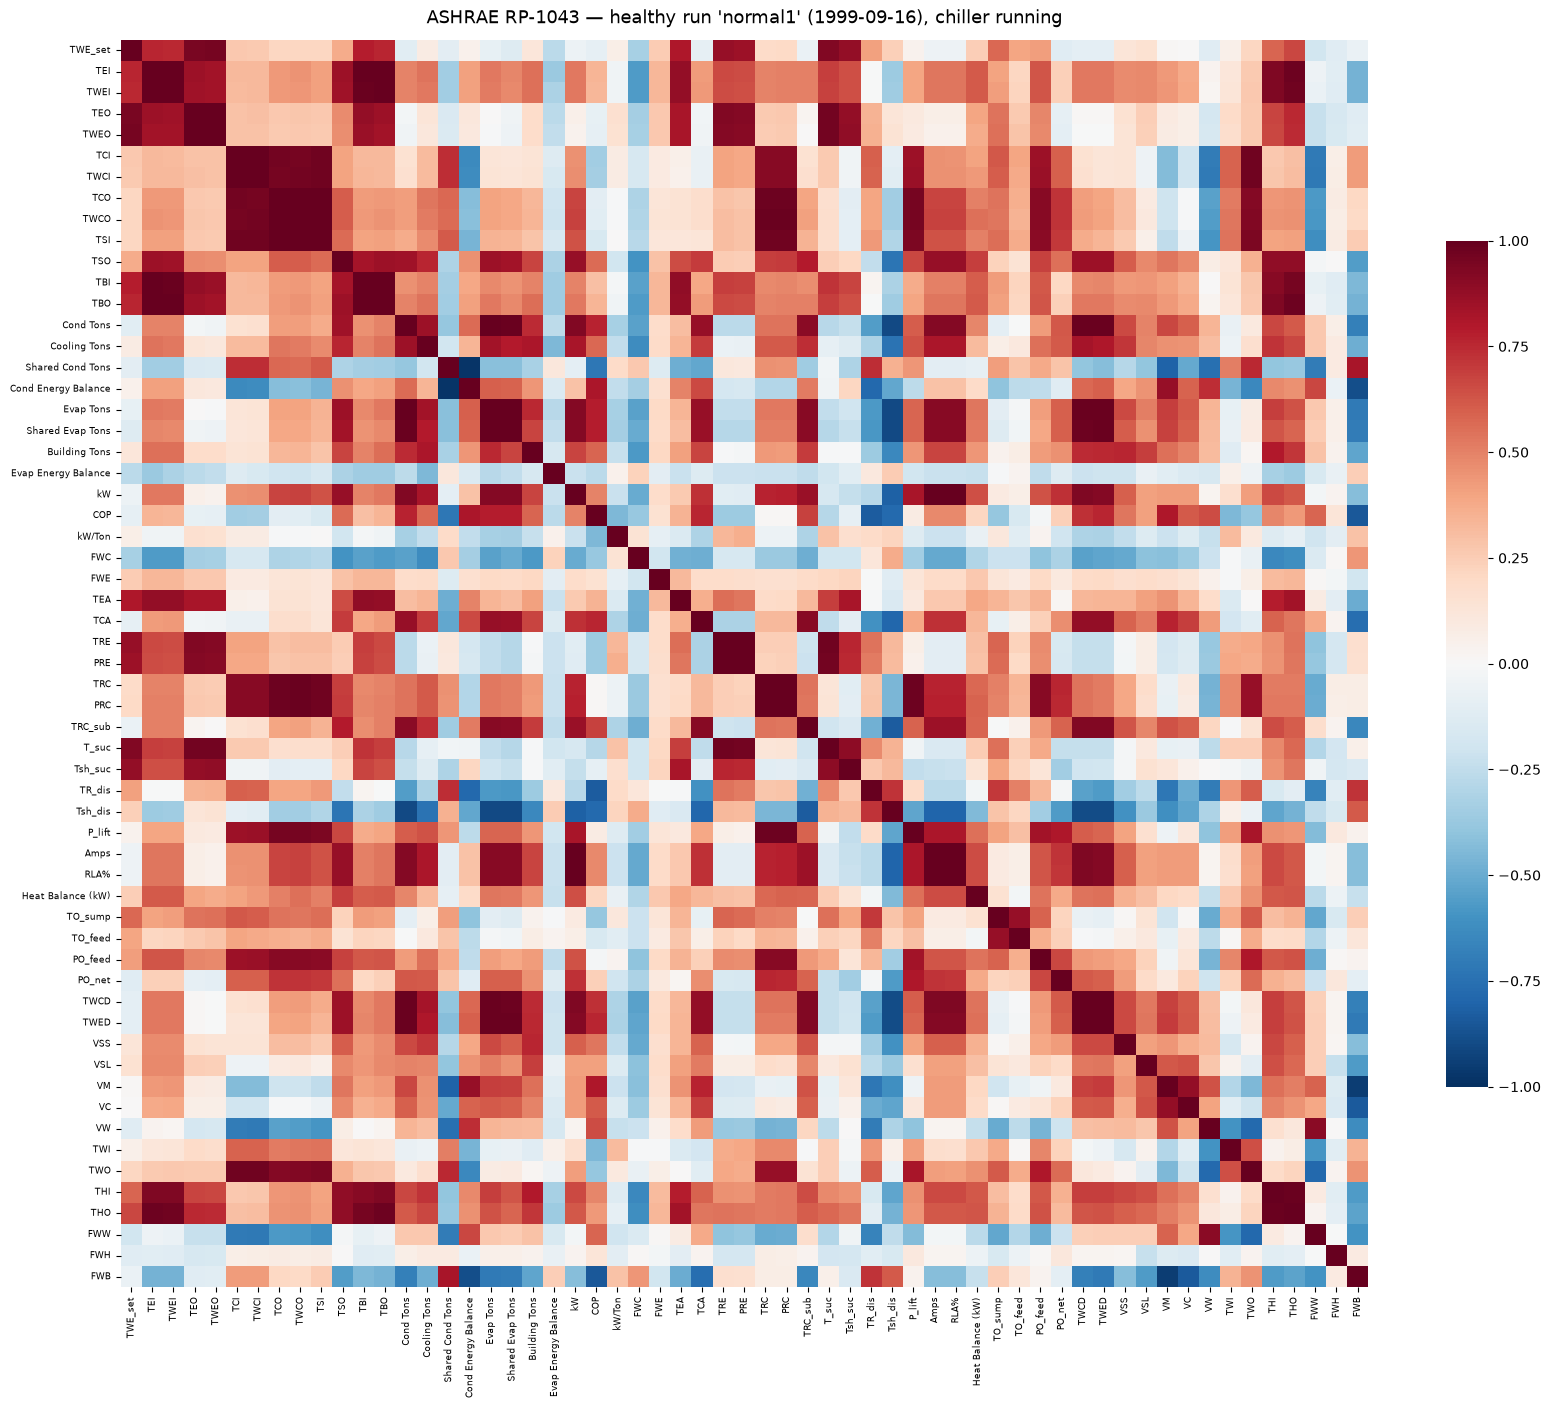

In [13]:
def plot_corr(corr: pl.DataFrame, cols: list[str], title: str, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(17, 15))
    sns.heatmap(
        corr.to_pandas(), xticklabels=cols, yticklabels=cols,
        cmap="RdBu_r", vmin=-1, vmax=1, annot=False, square=True,
        cbar_kws={"shrink": 0.6}, ax=ax,
    )
    ax.set_title(title, fontsize=13, pad=12)
    ax.tick_params(labelsize=6.5)
    return ax


corr_healthy = healthy_on.select(sensor_cols).drop_nulls().corr()
corr_faulty = faulty_on.select(sensor_cols).drop_nulls().corr()

plot_corr(corr_healthy, sensor_cols,
          f"ASHRAE RP-1043 — healthy run '{HEALTHY}' (1999-09-16), chiller running")
plt.tight_layout()
plt.show()

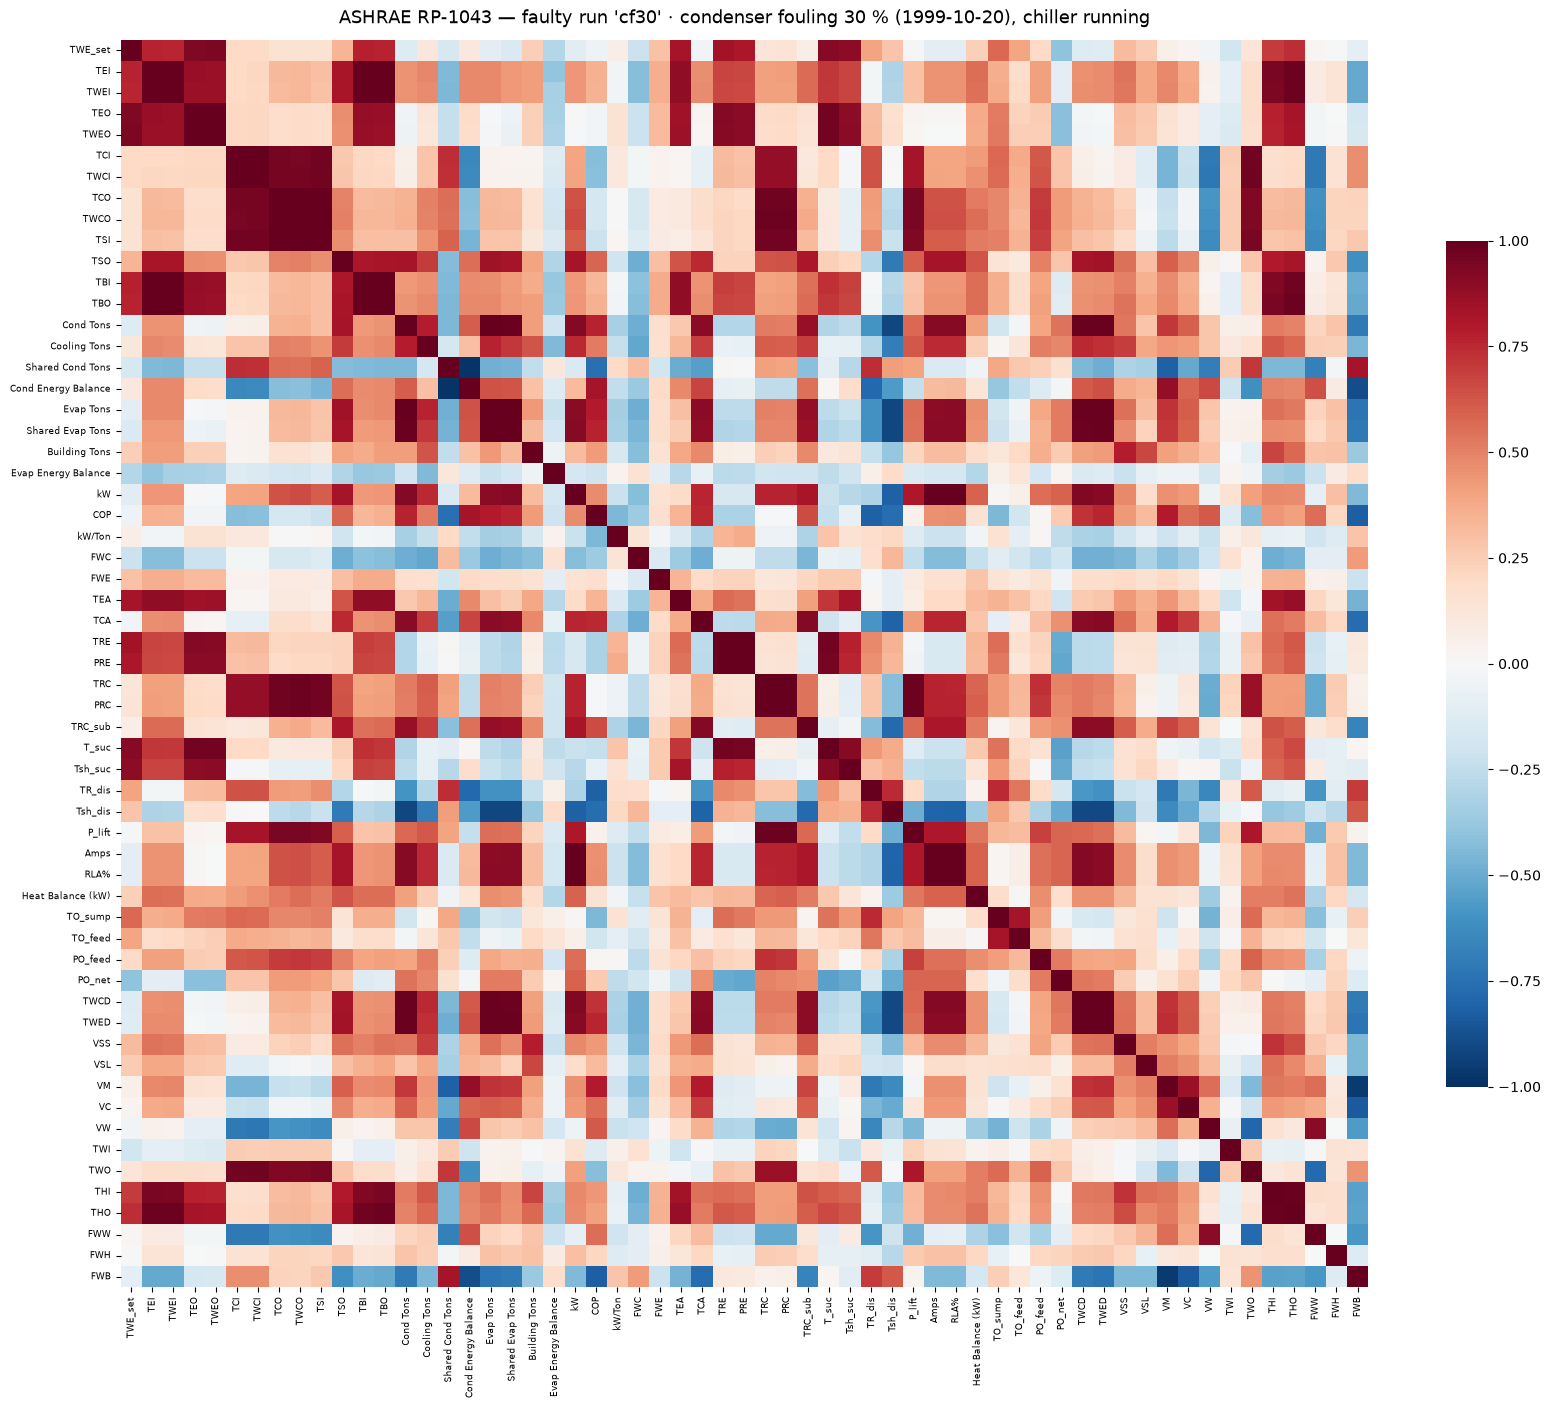

In [14]:
plot_corr(corr_faulty, sensor_cols,
          f"ASHRAE RP-1043 — faulty run '{FAULTY}' · condenser fouling 30 % (1999-10-20), chiller running")
plt.tight_layout()
plt.show()

### 4.1 Where the fault changes the correlation structure

The two matrices look alike at a glance — which is itself the point: **a fault is not visible as
a gross reshuffle of the correlation structure, it is a shift of specific pairs.** Subtracting
them isolates exactly those pairs.

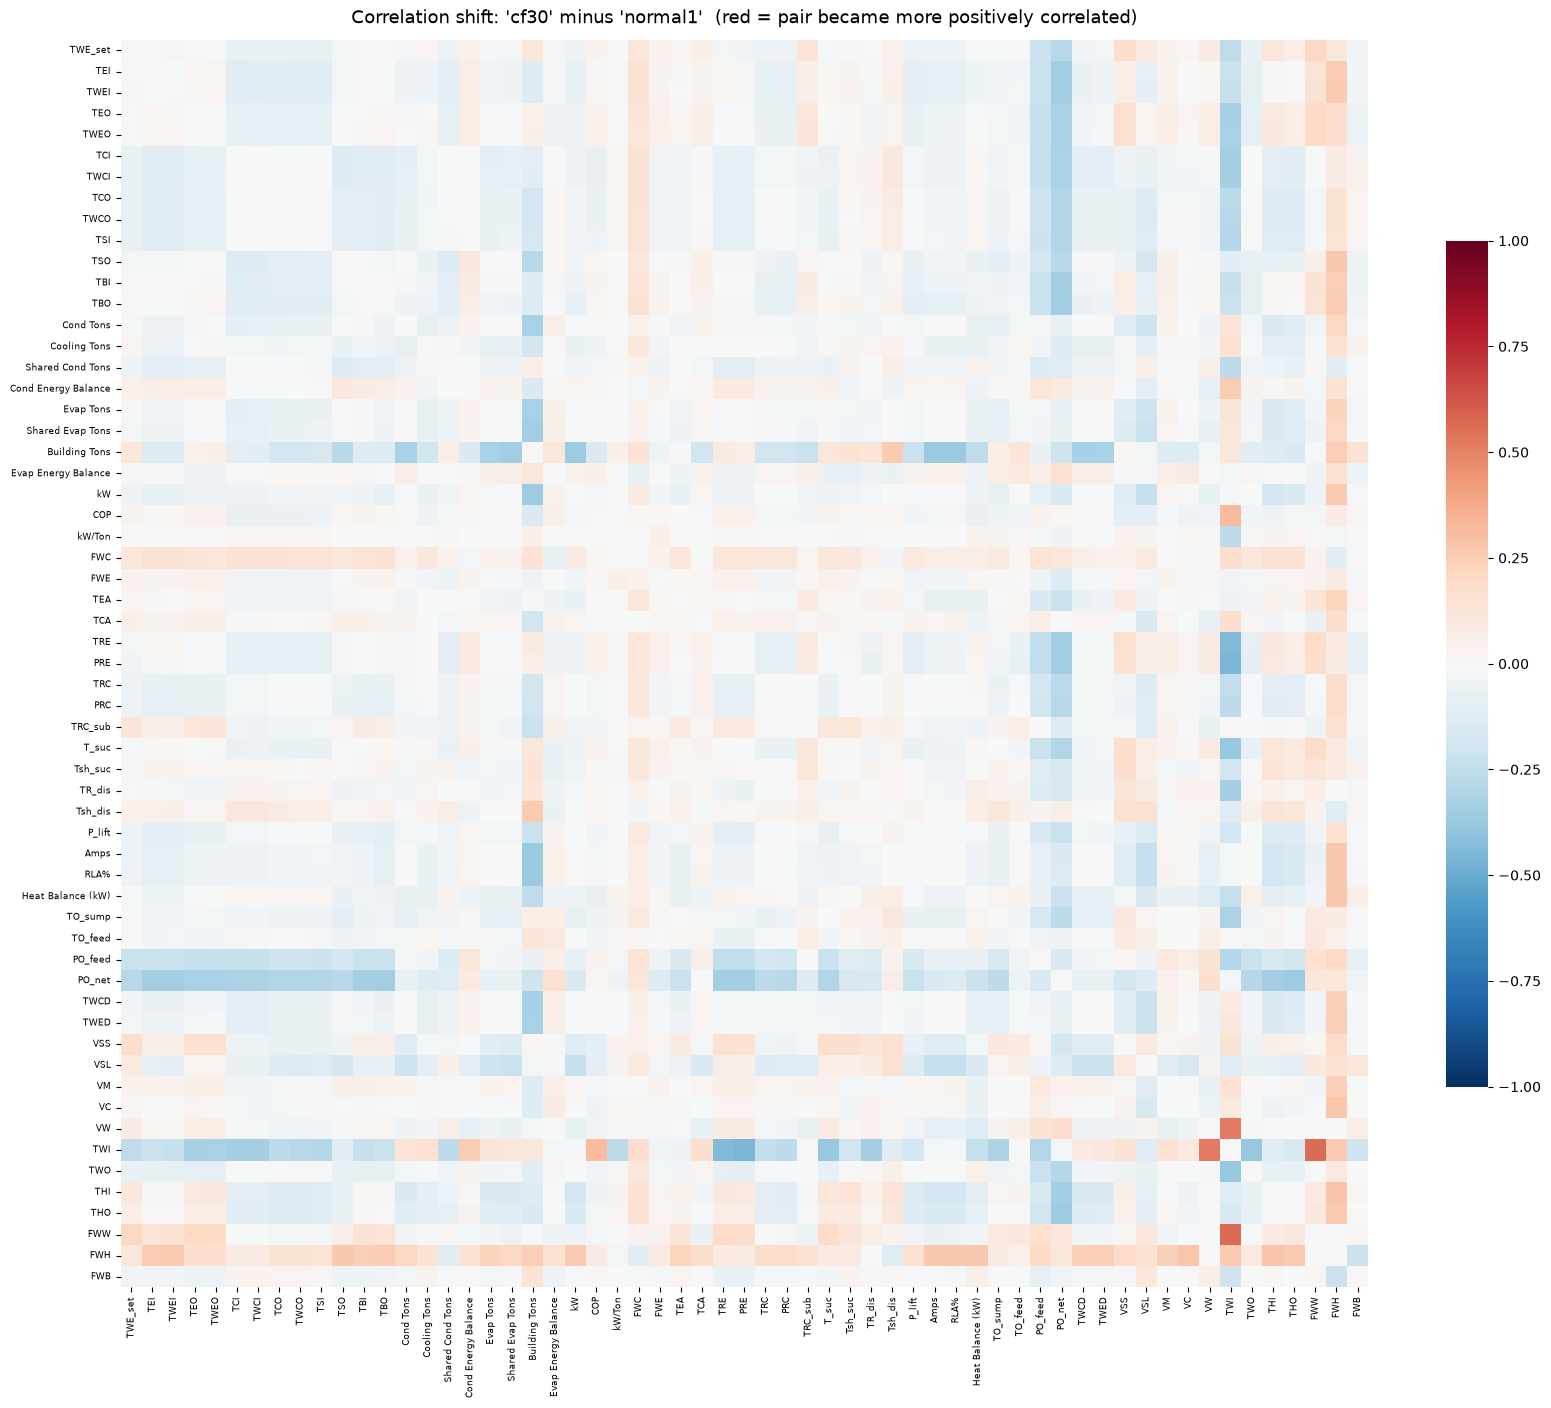

In [15]:
delta_corr = corr_faulty.to_numpy() - corr_healthy.to_numpy()

fig, ax = plt.subplots(figsize=(17, 15))
sns.heatmap(
    delta_corr, xticklabels=sensor_cols, yticklabels=sensor_cols,
    cmap="RdBu_r", vmin=-1, vmax=1, annot=False, square=True,
    cbar_kws={"shrink": 0.6}, ax=ax,
)
ax.set_title(f"Correlation shift: '{FAULTY}' minus '{HEALTHY}'  (red = pair became more positively correlated)",
             fontsize=13, pad=12)
ax.tick_params(labelsize=6.5)
plt.tight_layout()
plt.show()

### 4.2 Ranked sensor pairs

The heatmap shows structure; the ranked table names it. Same unpivot-and-deduplicate trick as
`eda.ipynb` cell 54.

In [16]:
def rank_pairs(corr: pl.DataFrame, cols: list[str]) -> pl.DataFrame:
    return (
        corr.with_columns(pl.Series("sensor_a", cols))
        .unpivot(index="sensor_a", variable_name="sensor_b", value_name="corr")
        .filter(pl.col("sensor_a") != pl.col("sensor_b"))
        .filter(pl.col("sensor_a") > pl.col("sensor_b"))   # deduplicate the mirrored half
        .drop_nans("corr")
        .with_columns(pl.col("corr").abs().alias("abs_corr"))
        .sort("abs_corr", descending=True)
    )


pairs_healthy = rank_pairs(corr_healthy, sensor_cols)

print(f"{pairs_healthy.height} distinct sensor pairs; "
      f"{pairs_healthy.filter(pl.col('abs_corr') > 0.95).height} of them above |r| = 0.95")

with pl.Config(tbl_rows=30, tbl_cols=-1, fmt_str_lengths=45, float_precision=4):
    display(pairs_healthy.head(30))

1711 distinct sensor pairs; 56 of them above |r| = 0.95


sensor_a,sensor_b,corr,abs_corr
str,str,f64,f64
"""RLA%""","""Amps""",0.9999,0.9999
"""TEI""","""TBO""",0.9998,0.9998
"""kW""","""Amps""",0.9984,0.9984
"""kW""","""RLA%""",0.9983,0.9983
"""TWCI""","""TCI""",0.9982,0.9982
"""TSI""","""TCO""",0.9978,0.9978
"""TWCO""","""TCO""",0.9976,0.9976
"""TRE""","""PRE""",0.9976,0.9976
"""TBO""","""TBI""",0.9975,0.9975


In [17]:
# the pairs whose relationship the fault changed the most
pairs_shift = (
    rank_pairs(corr_healthy, sensor_cols).rename({"corr": "corr_healthy"}).drop("abs_corr")
    .join(rank_pairs(corr_faulty, sensor_cols).rename({"corr": "corr_faulty"}).drop("abs_corr"),
          on=["sensor_a", "sensor_b"], how="inner")
    .with_columns((pl.col("corr_faulty") - pl.col("corr_healthy")).alias("delta"))
    .with_columns(pl.col("delta").abs().alias("abs_delta"))
    .sort("abs_delta", descending=True)
    .drop("abs_delta")
)

with pl.Config(tbl_rows=25, tbl_cols=-1, fmt_str_lengths=45, float_precision=4):
    display(pairs_shift.head(25))

sensor_a,sensor_b,corr_healthy,corr_faulty,delta
str,str,f64,f64,f64
"""TWI""","""FWW""",-0.5893,-0.0200,0.5693
"""VW""","""TWI""",-0.5940,-0.0738,0.5202
"""TWI""","""PRE""",0.3898,-0.0689,-0.4587
"""TWI""","""TRE""",0.3708,-0.0686,-0.4394
"""T_suc""","""TWI""",0.2459,-0.1363,-0.3822
"""TWO""","""TWI""",0.6407,0.2638,-0.3769
"""RLA%""","""Building Tons""",0.6758,0.3054,-0.3704
"""Building Tons""","""Amps""",0.6749,0.3053,-0.3696
"""kW""","""Building Tons""",0.6789,0.3171,-0.3618


## 5. PCA — the three primary components

PCA on **standardised** data is the eigendecomposition of exactly the correlation matrix plotted
above, so the components below *are* the dominant structures of that plot.

Two deliberate choices:

* **Fit once, on the healthy run only** (and only on its running samples, see §3.7). The scaler and the PCA basis are a model of *normal*
  behaviour. Everything else — the faulty run, the whole campaign — is then `transform`ed into
  that fixed basis. If we refit per view, the axes (and their arbitrary signs) would differ and
  the plots would not be comparable. It also makes the PC scores directly readable as a
  *deviation-from-normal* coordinate, which is what an FDD model would use.
* **The same three components for both time scales**, so the campaign plot and the single-day
  plot are the same axes at two zoom levels.

In [18]:
X_healthy = healthy_on.select(sensor_cols).drop_nulls().to_numpy()

scaler = StandardScaler().fit(X_healthy)
pca = PCA().fit(scaler.transform(X_healthy))

evr = pca.explained_variance_ratio_
print("Variance captured by the first 10 PCs:")
print(np.round(evr[:10], 4))
print("\nCumulative:")
print(np.round(np.cumsum(evr[:10]), 4))
print(f"\nPC1-PC3 together capture {evr[:3].sum():.1%} of the variance "
      f"of the {len(sensor_cols)} standardised channels.")

Variance captured by the first 10 PCs:
[0.3932 0.2448 0.1671 0.032  0.0279 0.0205 0.0162 0.0148 0.0138 0.0115]

Cumulative:
[0.3932 0.6379 0.8051 0.8371 0.8651 0.8855 0.9017 0.9165 0.9304 0.9418]

PC1-PC3 together capture 80.5% of the variance of the 59 standardised channels.


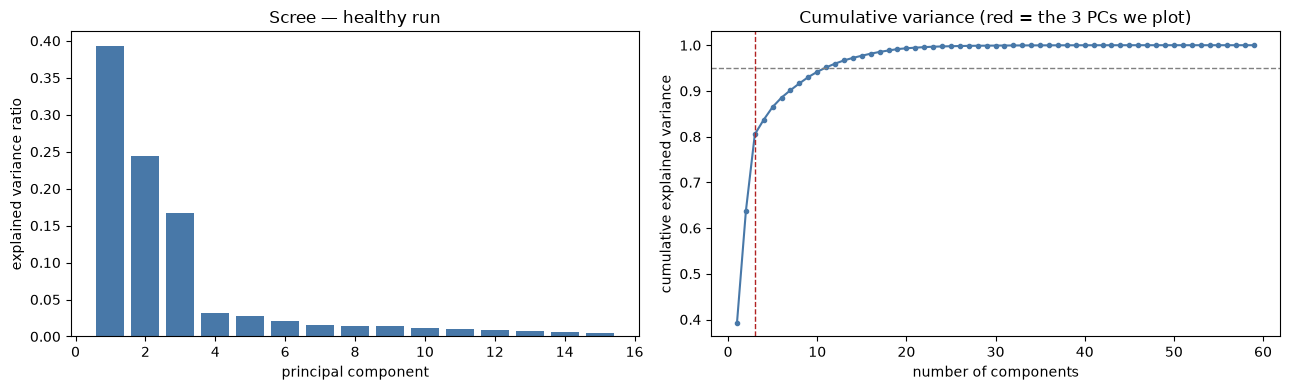

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.bar(range(1, 16), evr[:15], color="#4878A8")
ax1.set_xlabel("principal component"); ax1.set_ylabel("explained variance ratio")
ax1.set_title("Scree — healthy run")
ax2.plot(range(1, len(evr) + 1), np.cumsum(evr), marker=".", color="#4878A8")
ax2.axhline(0.95, ls="--", lw=1, color="grey")
ax2.axvline(3, ls="--", lw=1, color="firebrick")
ax2.set_xlabel("number of components"); ax2.set_ylabel("cumulative explained variance")
ax2.set_title("Cumulative variance (red = the 3 PCs we plot)")
plt.tight_layout(); plt.show()

### 5.1 What the three components mean

A principal component is only interpretable through its loadings. For each of PC1–PC3 we list the
channels with the largest |loading| — those are the sensors that *define* the axis.

In [20]:
N_PCS = 3
PC_NAMES = [f"PC{i+1}" for i in range(N_PCS)]

loadings = pl.DataFrame(pca.components_[:N_PCS].T, schema=PC_NAMES).with_columns(
    pl.Series("sensor", sensor_cols)
).select("sensor", *PC_NAMES)

for pc in PC_NAMES:
    top = (
        loadings.select("sensor", pc)
        .with_columns(pl.col(pc).abs().alias("abs_loading"))
        .sort("abs_loading", descending=True)
        .head(8)
        .with_columns((pl.col(pc) ** 2).alias("contribution"))
    )
    print(f"=== {pc}  ({evr[PC_NAMES.index(pc)]:.1%} of variance) ===")
    with pl.Config(tbl_rows=-1, fmt_str_lengths=45, float_precision=4):
        display(top.drop("abs_loading"))

=== PC1  (39.3% of variance) ===


sensor,PC1,contribution
str,f64,f64
"""TSO""",0.2029,0.0412
"""THI""",0.1872,0.0351
"""kW""",0.1862,0.0347
"""Amps""",0.1860,0.0346
"""RLA%""",0.1859,0.0346
"""THO""",0.1838,0.0338
"""TWCD""",0.1807,0.0327
"""Evap Tons""",0.1799,0.0324


=== PC2  (24.5% of variance) ===


sensor,PC2,contribution
str,f64,f64
"""TR_dis""",0.2358,0.0556
"""VW""",-0.2178,0.0474
"""FWW""",-0.2146,0.0461
"""TWO""",0.2134,0.0455
"""TCI""",0.2097,0.0440
"""TWCI""",0.2090,0.0437
"""Cond Energy Balance""",-0.2089,0.0436
"""Shared Cond Tons""",0.2050,0.0420


=== PC3  (16.7% of variance) ===


sensor,PC3,contribution
str,f64,f64
"""Tsh_suc""",0.2866,0.0821
"""T_suc""",0.2496,0.0623
"""TWE_set""",0.2430,0.0590
"""TWEO""",0.2426,0.0588
"""TEO""",0.2417,0.0584
"""TEA""",0.2264,0.0512
"""PRE""",0.2086,0.0435
"""TRE""",0.2081,0.0433


In [21]:
# a short human-readable label for each PC, built from its top-3 loading channels
def pc_label(pc: str) -> str:
    top3 = (
        loadings.select("sensor", pc)
        .with_columns(pl.col(pc).abs().alias("a"))
        .sort("a", descending=True)
        .head(3)["sensor"].to_list()
    )
    i = PC_NAMES.index(pc)
    return f"{pc} ({evr[i]:.0%} var) — {', '.join(top3)}"


PC_LABELS = {pc: pc_label(pc) for pc in PC_NAMES}
for v in PC_LABELS.values():
    print(v)

PC1 (39% var) — TSO, THI, kW
PC2 (24% var) — TR_dis, VW, FWW
PC3 (17% var) — Tsh_suc, T_suc, TWE_set


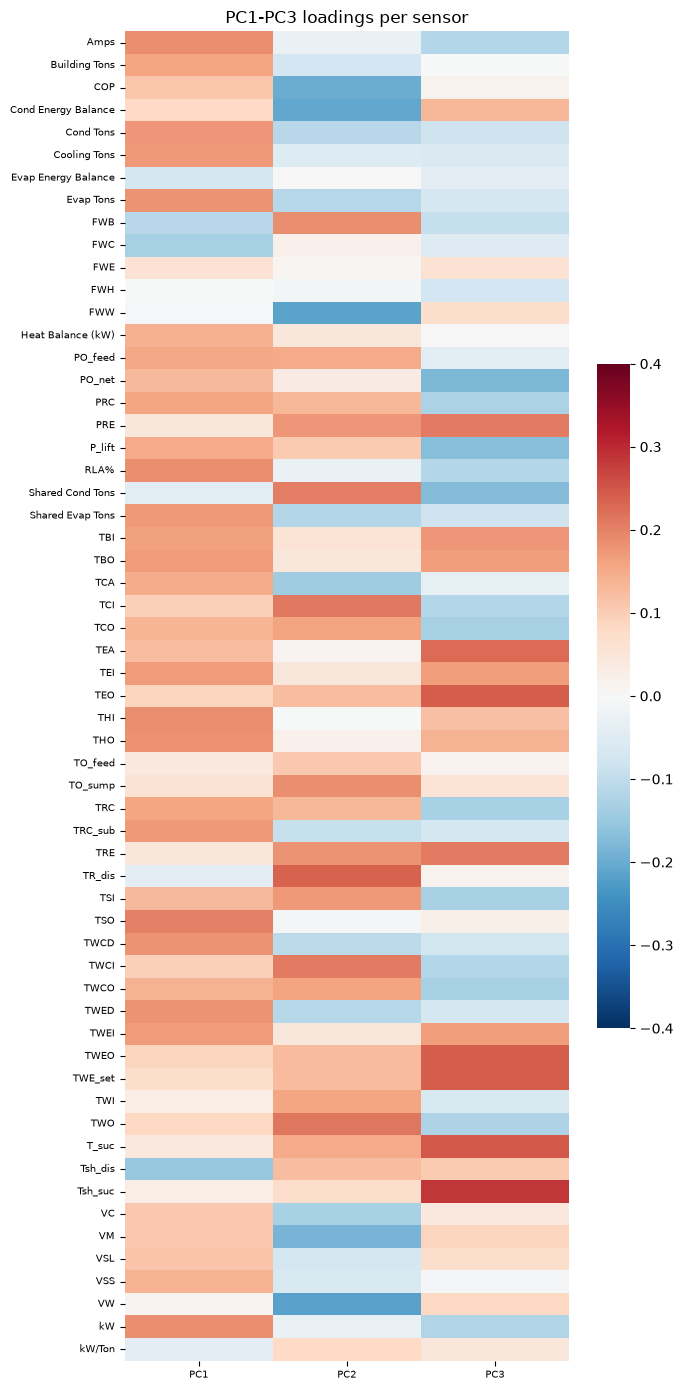

In [22]:
fig, ax = plt.subplots(figsize=(7, 14))
order = loadings.sort("sensor")
sns.heatmap(
    order.select(PC_NAMES).to_pandas(),
    yticklabels=order["sensor"].to_list(), xticklabels=PC_NAMES,
    cmap="RdBu_r", vmin=-0.4, vmax=0.4, center=0, ax=ax, cbar_kws={"shrink": 0.5},
)
ax.set_title("PC1-PC3 loadings per sensor", fontsize=12)
ax.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

### 5.2 PC1–PC3 over the **whole timespan** of the dataset

"The whole timespan" for RP-1043 means the **entire 1999-08-19 → 1999-11-09 campaign**, not one
file — a single workbook only covers one ~14 h test. So we load all 60 runs, project each into
the healthy PCA basis and plot the scores against their real test dates.

Loading all workbooks takes ~30 s.

In [23]:
frames, unreadable = [], []
raw_n = dropped_off = dropped_corrupt = 0
for row in catalogue.iter_rows(named=True):
    if row["test_date"] is None:
        continue
    try:
        f = load_test(row["path"], row["test_date"], row["test"], row["fault_family"])
    except Exception as exc:                      # one workbook is corrupt, see below
        unreadable.append((row["test"], type(exc).__name__))
        continue
    raw_n += f.height
    kept = f.filter(CLEAN)
    dropped_off += f.filter(~RUNNING).height
    dropped_corrupt += f.filter(RUNNING & ~PLAUSIBLE).height
    frames.append(kept.select("timestamp", "test", "fault_family", *sensor_cols))

campaign = pl.concat(frames, how="vertical")
del frames

if unreadable:
    print("workbooks that could not be parsed:", unreadable)
print(f"{len(catalogue) - len(unreadable)} of {len(catalogue)} test runs loaded")
print(f"raw samples          : {raw_n:,}")
print(f"  dropped, chiller off: {dropped_off:,} ({dropped_off / raw_n:.3%})")
print(f"  dropped, corrupted  : {dropped_corrupt:,} ({dropped_corrupt / raw_n:.3%})\n")

print(f"campaign: {campaign.shape[0]:,} samples x {campaign.shape[1]} columns")
print(f"          {campaign['timestamp'].min()} -> {campaign['timestamp'].max()}")
campaign.group_by("fault_family").len().sort("len", descending=True)

workbooks that could not be parsed: [('near normal1', 'CalamineError')]
58 of 59 test runs loaded
raw samples          : 299,194
  dropped, chiller off: 10,272 (3.433%)
  dropped, corrupted  : 32 (0.011%)

campaign: 288,890 samples x 62 columns
          1999-08-19 00:06:13.700000 -> 1999-11-09 14:18:00


fault_family,len
str,u32
"""Normal / benchmark""",87032
"""Non-condensables in refrigeran…",37794
"""Reduced evaporator water flow""",30665
"""Excess oil""",26090
"""Reduced condenser water flow""",25553
"""Refrigerant leak""",25550
"""Condenser fouling""",25544
"""Refrigerant overcharge""",20443
"""Multiple faults""",5111


In [24]:
def project(df: pl.DataFrame) -> pl.DataFrame:
    # project a frame into the healthy PCA basis, keeping the label columns
    scores = pca.transform(scaler.transform(df.select(sensor_cols).to_numpy()))[:, :N_PCS]
    keep = [c for c in ("timestamp", "test", "fault_family") if c in df.columns]
    return df.select(keep).hstack(pl.DataFrame(scores, schema=PC_NAMES))


campaign_pc = project(campaign)
campaign_pc.head()

timestamp,test,fault_family,PC1,PC2,PC3
datetime[μs],str,str,f64,f64,f64
1999-08-19 00:06:13.700,"""defective pilot valve""","""Defective Pilot Valve""",2.693694,6.898476,20.986928
1999-08-19 00:06:23.700,"""defective pilot valve""","""Defective Pilot Valve""",2.528209,6.352447,20.713495
1999-08-19 00:06:33.700,"""defective pilot valve""","""Defective Pilot Valve""",2.011567,5.776886,20.097007
1999-08-19 00:06:43.700,"""defective pilot valve""","""Defective Pilot Valve""",3.302097,3.398807,18.793008
1999-08-19 00:06:53.700,"""defective pilot valve""","""Defective Pilot Valve""",3.6511,2.50897,18.098451


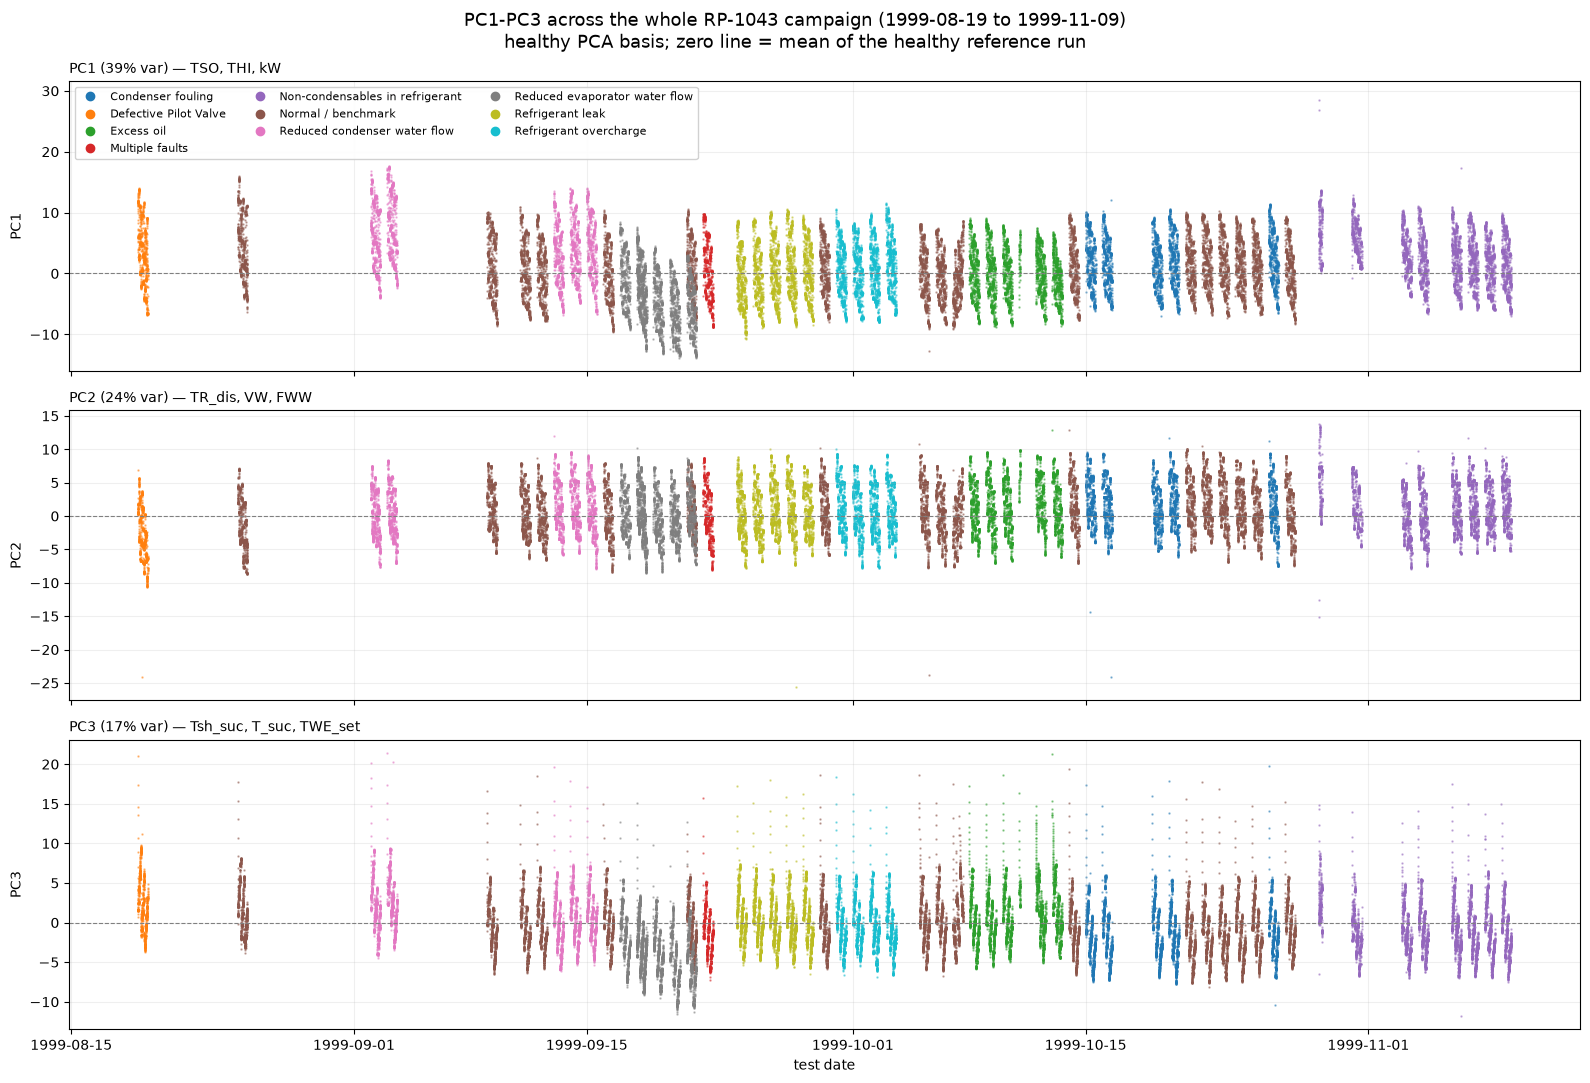

In [25]:
# every 6th sample = 1 point per minute; enough resolution for a 3-month axis, small enough to draw
plot_df = campaign_pc.gather_every(6).sort("timestamp")

families = sorted(plot_df["fault_family"].unique().to_list())
palette = dict(zip(families, sns.color_palette("tab10", len(families)).as_hex()))

fig, axes = plt.subplots(N_PCS, 1, figsize=(16, 11), sharex=True)
for ax, pc in zip(axes, PC_NAMES):
    for fam in families:
        sub = plot_df.filter(pl.col("fault_family") == fam)
        ax.scatter(sub["timestamp"], sub[pc], s=0.6, alpha=0.45,
                   color=palette[fam], label=fam, rasterized=True)
    ax.axhline(0, lw=0.8, color="grey", ls="--")
    ax.set_ylabel(pc)
    ax.set_title(PC_LABELS[pc], fontsize=10, loc="left")
    ax.grid(alpha=0.2)

handles = [plt.Line2D([], [], marker="o", ls="", color=palette[f], label=f) for f in families]
axes[0].legend(handles=handles, loc="upper left", fontsize=8, ncol=3, framealpha=0.9)
axes[-1].set_xlabel("test date")
fig.suptitle("PC1-PC3 across the whole RP-1043 campaign (1999-08-19 to 1999-11-09)\n"
             "healthy PCA basis; zero line = mean of the healthy reference run",
             fontsize=13)
plt.tight_layout(); plt.show()

Each vertical band is one test day. Because the axis is a real calendar and the rig ran roughly
one test per day, the campaign reads as a sequence of fault families: the flow-rate faults in
mid-September, the refrigerant charge sweep at the end of September, oil overcharge in early
October, condenser fouling mid-October, and the non-condensables tests in November.

The per-test view below makes the separation easier to read — one marker per test run
(median over the run) instead of one per sample.

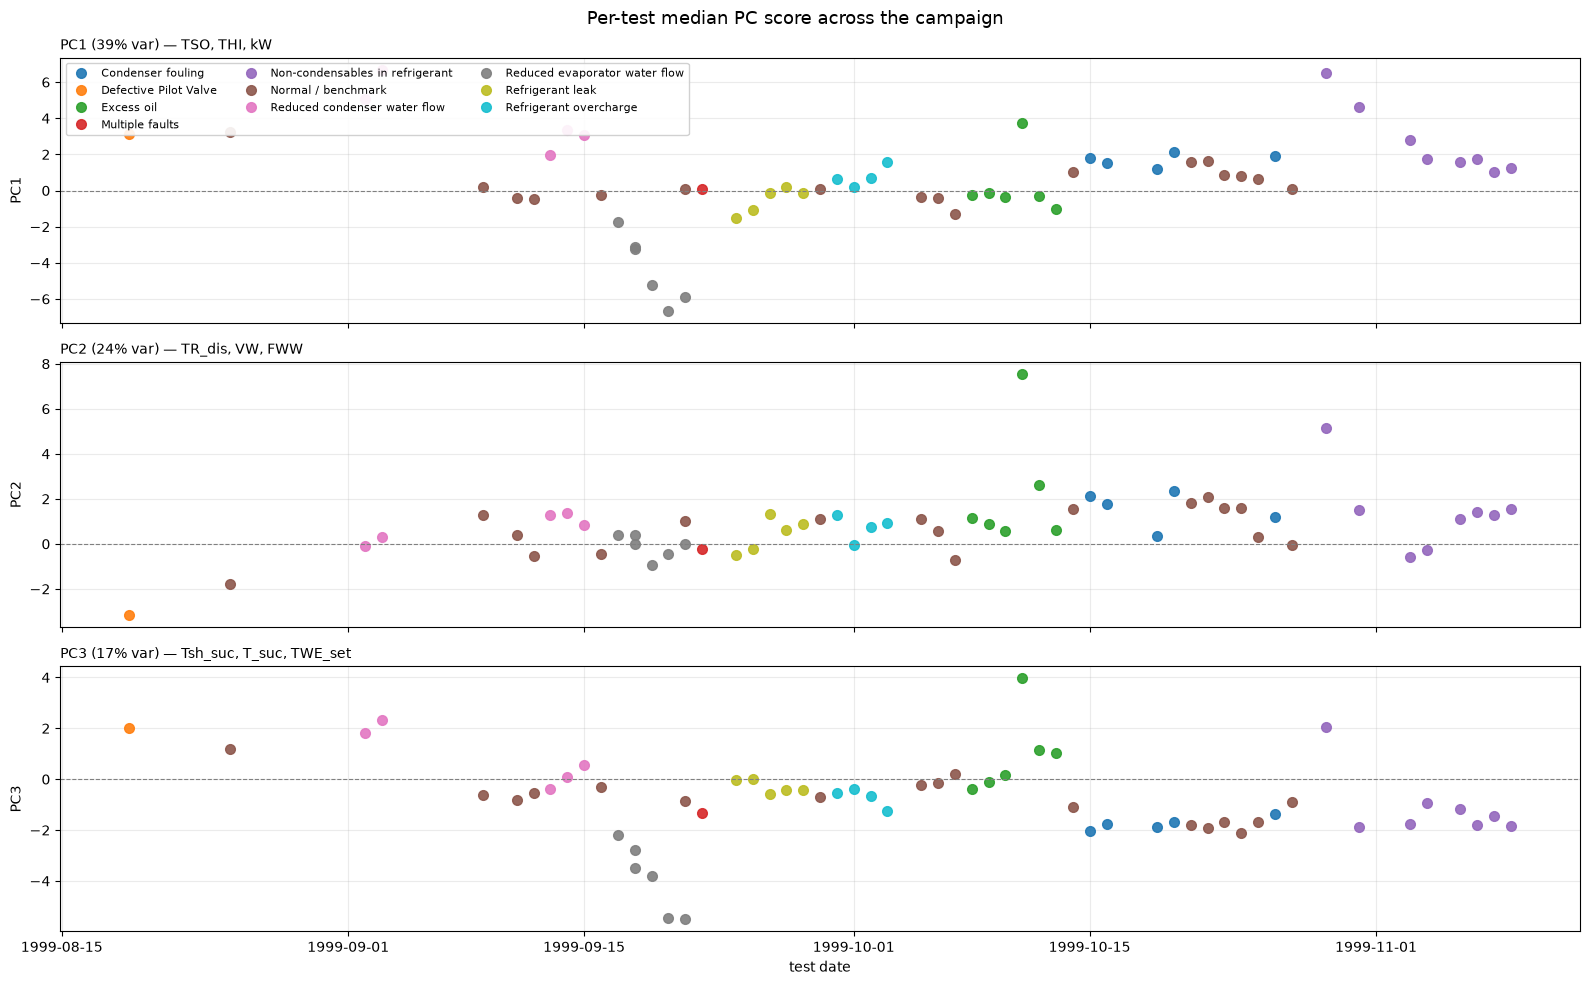

In [26]:
per_test = (
    campaign_pc.group_by("test", "fault_family")
    .agg(pl.col(PC_NAMES).median(), pl.col("timestamp").min().alias("test_date"))
    .sort("test_date")
)

fig, axes = plt.subplots(N_PCS, 1, figsize=(16, 10), sharex=True)
for ax, pc in zip(axes, PC_NAMES):
    for fam in families:
        sub = per_test.filter(pl.col("fault_family") == fam)
        ax.plot(sub["test_date"], sub[pc], "o", ms=7, color=palette[fam], label=fam, alpha=0.9)
    ax.axhline(0, lw=0.8, color="grey", ls="--")
    ax.set_ylabel(pc); ax.grid(alpha=0.25)
    ax.set_title(PC_LABELS[pc], fontsize=10, loc="left")
axes[0].legend(loc="upper left", fontsize=8, ncol=3, framealpha=0.9)
axes[-1].set_xlabel("test date")
fig.suptitle("Per-test median PC score across the campaign", fontsize=13)
plt.tight_layout(); plt.show()

**Read-out of the per-test view.** Several fault families separate on these three axes without
any classifier being involved:

* **Reduced evaporator water flow** (grey, mid-September) is the most distinctive — it drives
  PC1 down to ≈ −7 and PC3 to ≈ −5.5, far outside the spread of the normal runs, and the
  displacement scales with the severity of the throttling (10 % → 40 %).
* **Non-condensables in refrigerant** (purple, November) pushes PC1 *up*, in the opposite
  direction, again monotonically with the amount of nitrogen injected.
* **Condenser fouling** (blue, mid-October) sits slightly high on PC1 and consistently low on
  PC3 — a smaller displacement, consistent with what §3.6 showed: fouling is a subtle fault at
  these severities.
* The **normal / benchmark** runs (brown) stay clustered near zero throughout the three months,
  which is the important negative result: the PCA basis does not drift with calendar time, so a
  displacement really does mean "not normal" rather than "later in the campaign".

Note also the ordering artefact: faults were tested in blocks, so *date* and *fault family* are
confounded by design. Never train on the time axis with this dataset.

### 5.3 PC1–PC3 over a **single day**

At full 10 s resolution, one test day shows what the campaign view smears out: the chiller is
stepped through its scripted grid of operating points, so the PC scores move as a **staircase**,
not as a smooth daily curve. The healthy and the faulty day follow the *same* script, which is
what makes them directly comparable.

In [27]:
day = (
    pl.concat([
        project(healthy_on.select("timestamp", "test", "fault_family", *sensor_cols))
          .with_columns(pl.lit(f"healthy · {HEALTHY}").alias("run")),
        project(faulty_on.select("timestamp", "test", "fault_family", *sensor_cols))
          .with_columns(pl.lit(f"faulty · {FAULTY} (cond. fouling 30%)").alias("run")),
    ])
    .with_columns(
        # hours since that run started, so the two days overlay on one axis
        ((pl.col("timestamp") - pl.col("timestamp").min().over("run"))
         .dt.total_seconds() / 3600).alias("hours_into_test")
    )
)

long = day.unpivot(
    index=["hours_into_test", "run"], on=PC_NAMES,
    variable_name="component", value_name="score",
).with_columns(pl.col("component").replace(PC_LABELS).alias("component_label"))

fig = px.line(
    long.sort("hours_into_test").to_pandas(),
    x="hours_into_test", y="score", color="run", facet_row="component_label",
    height=850,
    labels={"hours_into_test": "hours into the test day", "score": "PC score"},
    title="PC1-PC3 over a single test day — healthy (1999-09-16) vs condenser fouling 30% (1999-10-20)",
)
fig.update_yaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1], font_size=10))
fig.update_layout(legend=dict(orientation="h", y=1.06, x=0), margin=dict(t=140))
fig.show()

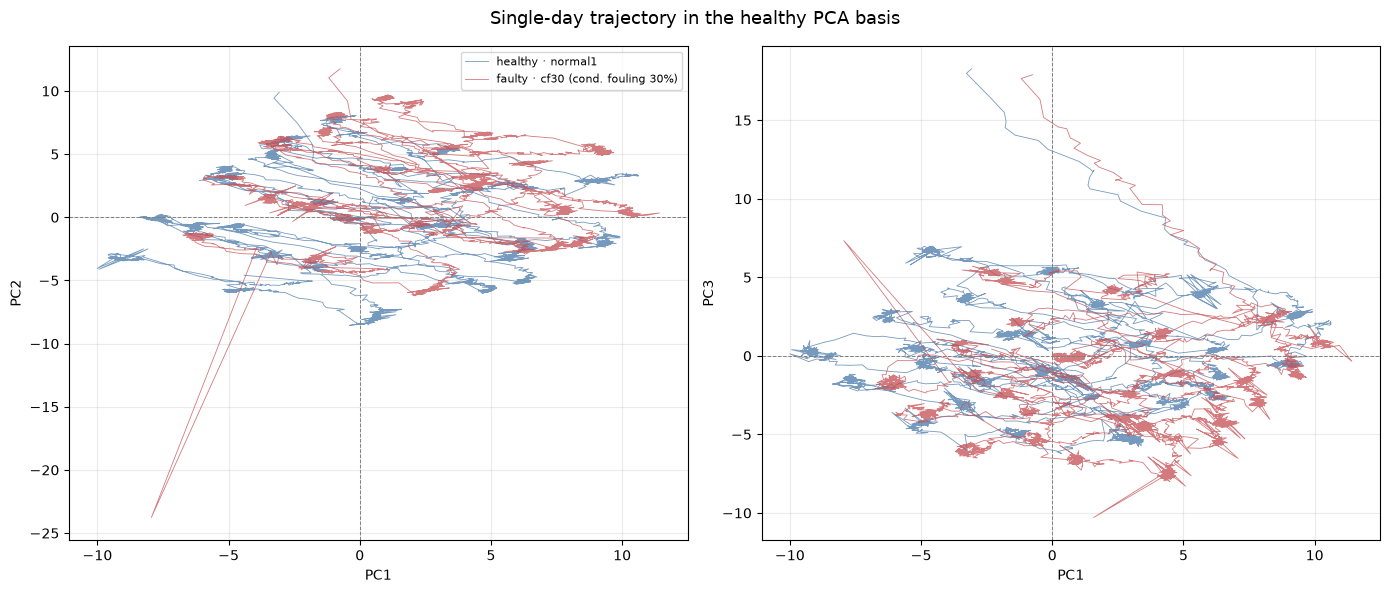

In [28]:
# the same day as a 2-D trajectory in the PC1/PC2 plane
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (xa, ya) in zip(axes, [("PC1", "PC2"), ("PC1", "PC3")]):
    for run, color in zip(day["run"].unique(maintain_order=True).to_list(), ["#4878A8", "#C44E52"]):
        sub = day.filter(pl.col("run") == run)
        ax.plot(sub[xa], sub[ya], lw=0.6, alpha=0.75, color=color, label=run)
    ax.axhline(0, lw=0.7, color="grey", ls="--"); ax.axvline(0, lw=0.7, color="grey", ls="--")
    ax.set_xlabel(xa); ax.set_ylabel(ya); ax.grid(alpha=0.25)
axes[0].legend(fontsize=8)
fig.suptitle("Single-day trajectory in the healthy PCA basis", fontsize=13)
plt.tight_layout(); plt.show()

**Read-out of the single-day view.** Both runs trace the *same* staircase, because both follow
the same scripted sequence of operating points — that is the point of the RP-1043 design. The
fault shows up not as a different shape but as a **consistent offset**: in the PC1/PC3 plane the
fouled run sits shifted relative to the healthy one over almost the whole day. The long spikes
leaving the cloud are the transients while the rig steps from one operating point to the next.

This is the practical lesson for a health indicator: **a single sample is not diagnostic** (the
clouds overlap heavily), but the *distribution* over a run is clearly displaced.

## 6. Summary — what to remember about ASHRAE RP-1043

**Structure**
* 59 workbooks = 59 scripted lab tests, **1999-08-19 → 1999-11-09**, one fault type and severity
  per file, fault family encoded in the folder name and the test date in `read me first.xls`.
  One of them (`near normal1.xls`) is corrupt, so **58 are usable**.
* Per test: **5191 rows × 66 columns, ≈ 14.4 h, nominal 10 s sampling**. `Time` is *elapsed
  seconds*, not a wall clock — the time-of-day in the derived `timestamp` is synthetic.
* Sheet `Complete Data Set` = raw 10 s; `Reduced Data Set` = 1-min averages; `Steady States` = one
  row per operating point.

**Quality**
* **Zero nulls, zero NaNs, no missing samples.** The cadence jitters between 9 s and 15 s around
  its 10 s nominal, but never long enough to drop a sample. Nothing to impute — the opposite of
  the production dataset in `eda.ipynb`, which makes RP-1043 a good clean-room reference for
  validating an FDD method before it meets real telemetry.
* `VH` and `VE` are constant across the campaign → dropped.
* `Unit Status` and `Active Fault` are controller *codes*, and `Tolerance%` / `Heat Balance%`
  are test-protocol bookkeeping → none of the four belongs in a correlation matrix or a PCA.
  Leaving `Tolerance%` in makes it the second-largest loading on PC1.
* Six channels (`TEA`, `TCA`, `Tsh_suc`, `Tsh_dis`, `P_lift`, `PO_net`) are exact algebraic
  combinations of others, which is where the saturated ±1 blocks in the correlation matrix come
  from.
* **Trap 1:** each run starts with a warm-up window (~1.5 % of samples) where the
  chiller is off and flow/power/capacity channels are stored as denormal zeros (`3.9e-45`), which
  also makes `COP` and `kW/Ton` blow up. Left in, these few dozen samples destroy the correlation
  of `FWC`, `FWE`, `COP`, `kW/Ton` and the heat-balance channels. Mask with `kW > 1` first.
* **Trap 2:** ~30 samples across 19 of the 58 files hold **corrupted values** from the old Excel
  writer — `5.8e30` °F, `4.1e13` kW. That is 0.011 % of the data, but one such sample is enough
  to hijack an entire principal component. Cut anything with `|value| > 1e4`; nothing legitimate
  in this dataset comes within four orders of magnitude of that.

**Structure of the signal**
* The channels are redundant in tight clusters rather than globally: only **56 of the 1711
  sensor pairs exceed |r| = 0.95**, but those clusters are enough that the first three PCs carry
  **80.5 %** of the variance of the 59 standardised channels (PC1 39 %, PC2 24 %, PC3 17 %).
* Because every test follows the same scripted load/temperature grid, PC1 tracks the **operating
  point** (load / capacity / power) rather than health. The fault signal shows up in the
  **residual** components and in the *shift* of specific correlation pairs — visible in §4.1 and
  in the per-test view of §5.2.

**Also in the folder**
* `11000.xlsx` — a pre-processed, pre-labelled 17-column extract (16 features + a `label` column)
  derived from this same campaign. Convenient as a ready-made classification benchmark, but it
  discards most channels, so this notebook builds from the raw `.xls` workbooks instead.